# Baseline Experiment

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import sys
from pathlib import Path
project_dir = Path.cwd().parent
sys.path.insert(0, str(project_dir))
from src.sparsification import *

In [2]:
df = pd.read_csv("cfs.csv")
T, taxa = build_tensor(df)

  edge  runs_retained  retention_percent  original_weight  total_weight  mean_weight
 t3-t5           6707              67.07            26.87    267117.856       26.712
 t4-t6           4989              49.89            14.77    150142.203       15.014
 t1-t4           5011              50.11            14.91    149705.566       14.971
 t4-t8           4851              48.51            14.59    143499.055       14.350
t3-t10           4838              48.38            14.34    143251.204       14.325
t5-t10           4798              47.98            14.18    139486.375       13.949
 t6-t8           4693              46.93            13.83    136414.019       13.641
 t1-t6           4717              47.17            13.56    136322.546       13.632
t7-t10           4593              45.93            13.26    132593.520       13.259
 t2-t8           4572              45.72            13.12    131809.613       13.181
 t1-t8           4528              45.28            13.29    1313

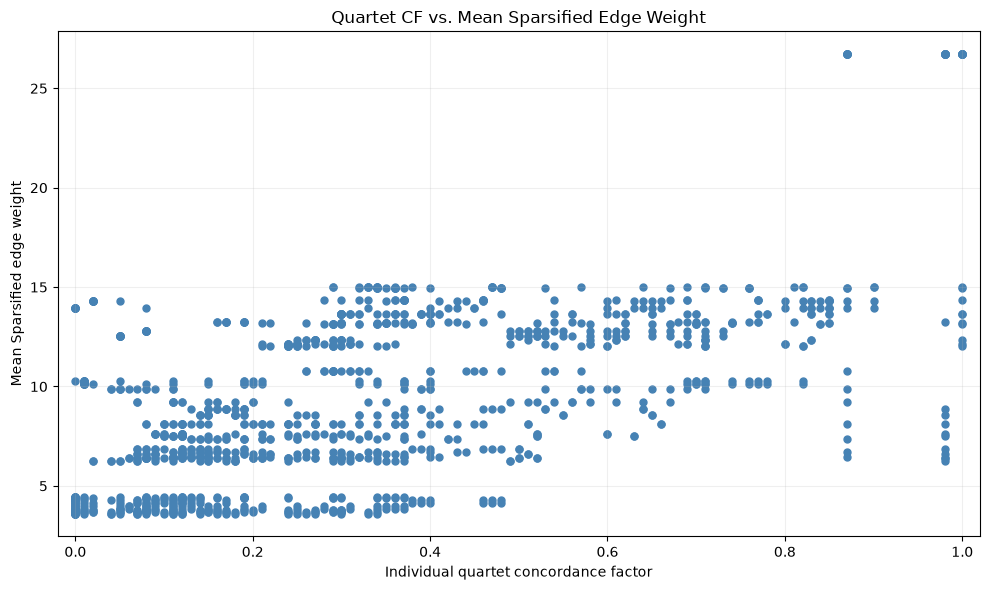

In [3]:
num_seeds = 10000
method = "sum"
num_samples = 20

W = collapse_tensor(T, method)
L = compute_laplacian(W)
R = compute_effective_resistance(L)
edge_list = compute_edge_sampling_probabilities(W, R, taxa)

# Each edge gets a list containing its weight from every run
weights_by_edge = {
    (i, j): []
    for i, j, w, r, s, p in edge_list
}

for seed in range(num_seeds):
    W_sparse = sample_edges(
        edge_list,
        num_samples=num_samples,
        n=len(taxa),
        taxa=taxa,
        seed=seed
    )

    for i, j in weights_by_edge:
        # Includes zero when the edge wasn't retained
        weights_by_edge[(i, j)].append(W_sparse[i, j])

# Summarize results for each edge
rows = []

W_mean = np.zeros_like(W, dtype=float)

for (i, j), weights in weights_by_edge.items():
    weights = np.array(weights)
    count = np.count_nonzero(weights > 0)
    mean_weight = np.mean(weights)

    W_mean[i, j] = mean_weight
    W_mean[j, i] = mean_weight

    rows.append({
        "edge": f"{taxa[i]}-{taxa[j]}",
        "runs_retained": count,
        "retention_percent": 100 * count / num_seeds,
        "original_weight": W[i, j],
        "total_weight": np.sum(weights),
        "mean_weight": mean_weight
    })

weight_df = (
    pd.DataFrame(rows)
    .sort_values("mean_weight", ascending=False)
    .reset_index(drop=True)
)

print(weight_df.round(3).to_string(index=False))
plot_cf_vs_sparse_weights(df, W_mean, taxa)

In [4]:
df = pd.read_csv("cfs.csv")

T, taxa = build_tensor(df)

In [5]:
W = collapse_tensor(T, "sum")

In [6]:
L = compute_laplacian(W)

In [7]:
R = compute_effective_resistance(L)

In [8]:
edge_list = compute_edge_sampling_probabilities(
    W, R, taxa
)

In [9]:
W_sparse = sample_edges(
    edge_list,
    num_samples=20,
    n=len(taxa),
    taxa=taxa,
    seed=42
)